# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ruchi74/flyrank-ml-internship/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

### Distribution Observations

The dataset contains 30,000 content records. Traffic variables show strong right-skewness: impressions have a skew of 11.38, clicks 18.35, and sessions 12.13. This indicates that a small number of content items receive much higher traffic than most others.

The trend percentage is also highly skewed (56.76), so extreme changes may affect summary statistics. Missing values are present in `word_count` (7,699), `search_volume` (2,468), and `trend_pct` (3,388). These missing values should be considered before further analysis. Overall, the distributions suggest that medians and percentiles can be more informative than means for understanding typical content performance.

,count,mean,std,min,50%,75%,90%,95%,99%,max,missing_count,skew
impressions_90d,30000.0,5200.37,16838.02,1.0,731.00,3615.25,12136.40,22996.50,73505.83,517715.0,0,11.38
clicks_90d,30000.0,16.10,75.08,0.0,1.00,7.00,32.00,69.05,253.01,4178.0,0,18.35
sessions_90d,30000.0,37.07,107.07,1.0,7.00,27.00,88.00,166.00,451.01,4345.0,0,12.13
search_volume,27532.0,158.88,1518.27,0.0,10.00,20.00,110.00,390.00,2900.00,74000.0,2468,26.02
word_count,22301.0,3107.76,1452.38,8.0,2877.00,3666.00,5327.00,6173.00,7292.00,9546.0,7699,0.94
content_age_days,30000.0,256.17,132.71,90.0,236.00,333.00,463.00,487.00,537.00,564.0,0,0.49
days_since_last_update,30000.0,46.10,42.08,1.0,20.00,104.00,104.00,104.00,106.00,373.0,0,1.16
ctr,30000.0,0.51,3.28,0.0,0.07,0.29,0.65,1.09,8.33,100.0,0,17.44
avg_position,30000.0,16.34,15.22,0.0,10.80,22.30,36.80,48.20,69.90,245.0,0,1.98
engagement_rate,30000.0,2.53,8.31,0.0,0.00,1.35,6.94,12.50,33.33,100.0,0,7.22


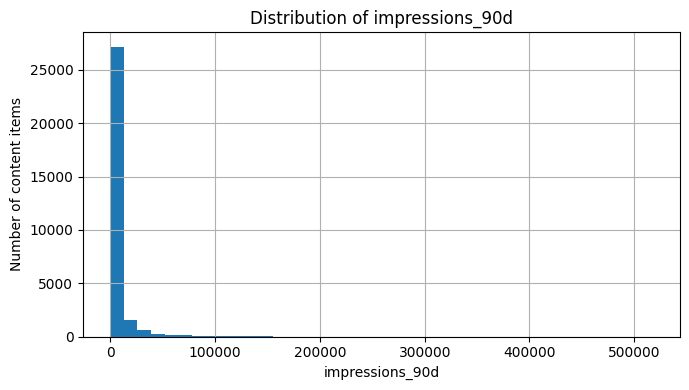

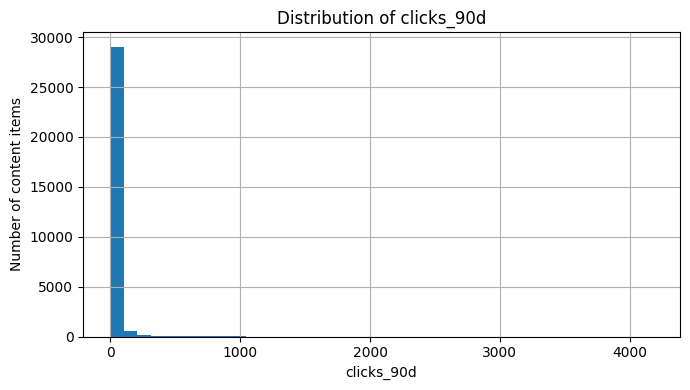

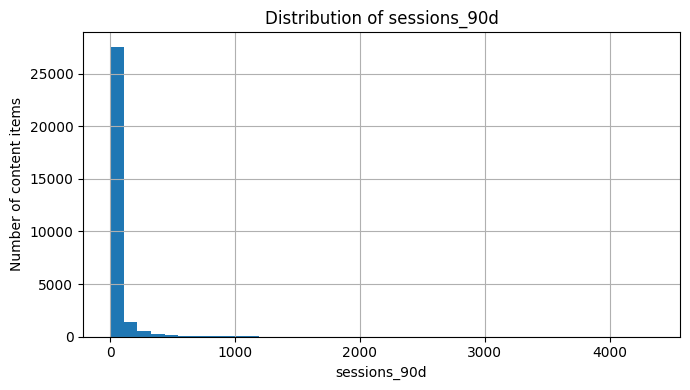

In [8]:

# Section 1: Distributions of key signals

import pandas as pd
import matplotlib.pyplot as plt

# Use the dataset already loaded above
key_columns = [
    "impressions_90d",
    "clicks_90d",
    "sessions_90d",
    "search_volume",
    "word_count",
    "content_age_days",
    "days_since_last_update",
    "ctr",
    "avg_position",
    "engagement_rate",
    "scroll_rate",
    "trend_pct"
]

# Keep only columns that exist in the dataset
key_columns = [c for c in key_columns if c in df.columns]

# Summary statistics
summary = df[key_columns].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
).T

summary["missing_count"] = df[key_columns].isna().sum()
summary["skew"] = df[key_columns].skew(numeric_only=True)

display(summary.round(2))

# Plot distributions of traffic signals
traffic_columns = [
    c for c in [
        "impressions_90d",
        "clicks_90d",
        "sessions_90d"
    ] if c in df.columns
]

for col in traffic_columns:
    plt.figure(figsize=(7, 4))
    df[col].dropna().hist(bins=40)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of content items")
    plt.tight_layout()
    plt.show()



## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

#### Signal Test #1: Low CTR on Visible Pages

**Hypothesis:** Pages with sufficient impressions and an average search position between 1 and 20 may still have low click-through rates (CTR).

**Method:** Selected pages with at least 500 impressions over 90 days and an average position between 1 and 20.

**Results:** Out of 12,023 eligible pages, 9,759 (81.17%) had CTR below 0.5. The median CTR was 0.21, and the median average position was 8.2.

**Verdict: CONFIRMED.** The results support investigating low CTR among visible pages. However, this test does not prove that every page with low CTR needs a CTR fix; search intent, query mix, and other factors may also influence CTR.

In [9]:

# Signal Test 1: Low CTR on visible pages

import pandas as pd

required = ["impressions_90d", "avg_position", "ctr"]
missing = [col for col in required if col not in df.columns]

if missing:
    print("Missing required columns:", missing)
else:
    eligible = df[
        (df["impressions_90d"] >= 500) &
        (df["avg_position"] > 0) &
        (df["avg_position"] <= 20)
    ].copy()

    eligible = eligible.dropna(subset=["ctr"])

    print("Eligible visible pages:", len(eligible))

    if len(eligible) > 0:
        low_ctr = eligible[eligible["ctr"] < 0.5]
        other_ctr = eligible[eligible["ctr"] >= 0.5]

        print("Pages with CTR below 0.5:", len(low_ctr))
        print("Percentage below 0.5:",
              round(100 * len(low_ctr) / len(eligible), 2), "%")
        print("Median CTR:", round(eligible["ctr"].median(), 3))
        print("Median average position:",
              round(eligible["avg_position"].median(), 2))
    else:
        print("No eligible pages found.")


Eligible visible pages: 12023
Pages with CTR below 0.5: 9759
Percentage below 0.5: 81.17 %
Median CTR: 0.21
Median average position: 8.2


#### Signal Test #2: Stale Content and Traffic Trends

**Hypothesis:** Older content that has not been updated for a long time may show more negative traffic trends.

**Method:** Compared pages with at least 500 impressions, separating pages not updated for 180 days or more from pages updated within the last 180 days.

**Results:** Only 17 eligible pages were stale, compared with 16,600 recently updated pages. Among stale pages, 94.12% had a downward trend, and the median trend percentage was -55.0. Among the other pages, 59.91% had a downward trend, and the median trend percentage was -29.9.

**Verdict: SUPPORTED, WITH CAUTION.** Stale pages showed more negative trends in this dataset. However, the stale group contains only 17 pages, so more data is needed before drawing a strong conclusion. This association does not prove that updating content will improve traffic.

In [10]:

# Signal Test 2: Stale content and traffic trends

required = [
    "days_since_last_update",
    "impressions_90d",
    "trend_pct"
]
missing = [col for col in required if col not in df.columns]

if missing:
    print("Missing required columns:", missing)
else:
    eligible = df[
        df["impressions_90d"] >= 500
    ].dropna(subset=["days_since_last_update", "trend_pct"]).copy()

    eligible["update_group"] = eligible[
        "days_since_last_update"
    ].apply(lambda days: "Stale (180+ days)"
            if days >= 180 else "Updated within 180 days")

    print("Eligible pages:", len(eligible))
    print("\nGroup summary:")
    display(
        eligible.groupby("update_group")["trend_pct"]
        .agg(["count", "median", "mean"])
        .round(2)
    )

    print("\nTrend direction by update group:")
    display(pd.crosstab(
        eligible["update_group"],
        df.loc[eligible.index, "trend_direction"],
        normalize="index"
    ).mul(100).round(2))


Eligible pages: 16617

Group summary:


,count,median,mean
update_group,,,
Stale (180+ days),17,-55.0,-56.15
Updated within 180 days,16600,-29.9,-11.10



Trend direction by update group:


trend_direction,down,stable,up
update_group,,,
Stale (180+ days),94.12,5.88,0.00
Updated within 180 days,59.91,26.13,13.96


#### Signal Test #3: Low Engagement on Pages with Traffic

**Hypothesis:** Pages receiving at least 30 sessions may still have low engagement.

**Method:** Examined pages with at least 30 sessions and classified a page as low engagement if either its engagement rate or scroll rate was below 30.

**Results:** Out of 7,114 eligible pages, 7,113 (99.99%) were classified as low engagement. The median engagement rate was 1.9, and the median scroll rate was 5.0. Among low-engagement pages, 54.62% had a downward trend, 31.70% were stable, and 13.27% had an upward trend.

**Verdict: MIXED.** Low engagement is common in this dataset, but the rule classifies nearly every eligible page as low engagement. Therefore, the threshold does not effectively distinguish pages that need attention. The definition and thresholds should be reviewed before using this signal for prioritization.

### What This Means in Practice

The audit suggests that low CTR and declining traffic on stale pages are useful signals to investigate, although the stale-page sample is small. The current low-engagement rule is too broad because it flags almost every eligible page. FlyRank should validate thresholds against more data and combine multiple signals before prioritizing content updates.

In [11]:

# Signal Test 3: Low engagement on pages with traffic

required = ["sessions_90d", "engagement_rate", "scroll_rate"]
missing = [col for col in required if col not in df.columns]

if missing:
    print("Missing required columns:", missing)
else:
    eligible = df[df["sessions_90d"] >= 30].copy()

    eligible["low_engagement"] = (
        (eligible["engagement_rate"] < 30) |
        (eligible["scroll_rate"] < 30)
    )

    print("Pages with at least 30 sessions:", len(eligible))
    print("Pages with low engagement:", int(eligible["low_engagement"].sum()))
    print(
        "Percentage with low engagement:",
        round(eligible["low_engagement"].mean() * 100, 2), "%"
    )

    print("\nMedian engagement and scroll rates:")
    display(
        eligible[["engagement_rate", "scroll_rate"]]
        .median()
        .to_frame("median")
        .round(2)
    )

    print("\nTrend direction for low-engagement pages:")
    display(
        eligible.loc[eligible["low_engagement"], "trend_direction"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
        .to_frame("percentage")
    )


Pages with at least 30 sessions: 7114
Pages with low engagement: 7113
Percentage with low engagement: 99.99 %

Median engagement and scroll rates:


,median
engagement_rate,1.9
scroll_rate,5.0



Trend direction for low-engagement pages:


,percentage
trend_direction,
down,54.62
stable,31.70
up,13.27
flat,0.21
new,0.20


In [12]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

## 4. What this means in practice

*Two or three sentences: what a content team should take from this.*

In [13]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


In [14]:
import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [".git", "__pycache__"]]
    for file in files:
        if file.endswith((".csv", ".py", ".md", ".json")):
            print(os.path.join(root, file))

/content/.config/.last_update_check.json
/content/sample_data/anscombe.json
/content/sample_data/README.md
/content/sample_data/mnist_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv


In [15]:
import pandas as pd

url = "https://raw.githubusercontent.com/Ruchi74/flyrank-ml-internship/main/data/raw/content_refresh_anonymized.csv"

df = pd.read_csv(url)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (30000, 44)

Column names:
['content_id', 'client_id', 'search_volume', 'competition', 'competition_level', 'cpc', 'content_type', 'main_intent', 'word_count', 'char_count', 'provider_used', 'model_used', 'impressions_90d', 'clicks_90d', 'pageviews_90d', 'sessions_90d', 'users_90d', 'engaged_sessions_90d', 'ai_sessions_90d', 'scroll_events_90d', 'days_with_impressions', 'days_with_sessions', 'impressions_last_30d', 'clicks_last_30d', 'sessions_last_30d', 'impressions_prev_30d', 'clicks_prev_30d', 'sessions_prev_30d', 'content_age_days', 'age_tier', 'age_tier_order', 'days_since_last_update', 'freshness_tier', 'word_count_tier', 'char_count_tier', 'ctr', 'avg_position', 'engagement_rate', 'scroll_rate', 'ai_traffic_pct', 'impression_tier', 'position_tier', 'trend_direction', 'trend_pct']

First 5 rows:


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,NaN,0.49,6.2,1.28,3.45,0.0,good,page_1,stable,-13.8
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,15000-25000,0.13,44.0,0.00,24.29,0.0,good,page_3_5,down,-34.7


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.